# Kronik Böbrek Hastalığı Analizi ve MLP Sınıflandırma
Bu notebook'ta Google Drive üzerindeki veri seti yüklenerek analiz edilecek ve Çok Katmanlı Algılayıcı (MLP) modelleri eğitilecektir.

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, accuracy_score

# Drive'ı bağla
drive.mount('/content/drive')

# Veri setini oku (Dosya yolunu kendi Drive yapınıza göre güncelleyin)
path = '/content/drive/MyDrive/Kidney Disease/kidney_disease_turkce.csv'
df = pd.read_csv(path)
df.head()

Mounted at /content/drive


,id,yas,kan_basinci,ozgul_agirlik,albumin,seker,kirmizi_kan_hucresi,irin_hucresi,irin_hucresi_kumesi,bakteri,...,paketli_hucre_hacmi,beyaz_kan_hucresi_sayisi,kirmizi_kan_hucresi_sayisi,hipertansiyon,diyabet,koroner_arter_hastaligi,istah,ayak_ödemi,anemi,siniflandirma
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


### 1. Veriyi Kavrama ve Ön İşleme
Eksik değerlerin kontrolü, veri tiplerinin incelenmesi ve kategorik değişkenlerin dönüştürülmesi.

In [ ]:
# Veri seti hakkında genel bilgi
print(df.info())

# 'id' sütununu gereksiz olduğu için atalım
if 'id' in df.columns:
    df = df.drop('id', axis=1)

# Eksik değerleri basitçe doldurma (Sayısal için ortalama, kategorik için mod)
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].mean())

# Kategorik verileri sayısal verilere dönüştürme
le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          400 non-null    int64  
 1   yas                         391 non-null    float64
 2   kan_basinci                 388 non-null    float64
 3   ozgul_agirlik               353 non-null    float64
 4   albumin                     354 non-null    float64
 5   seker                       351 non-null    float64
 6   kirmizi_kan_hucresi         248 non-null    object 
 7   irin_hucresi                335 non-null    object 
 8   irin_hucresi_kumesi         396 non-null    object 
 9   bakteri                     396 non-null    object 
 10  rastgele_kan_sekeri         356 non-null    float64
 11  kan_ure                     381 non-null    float64
 12  serum_kreatinin             383 non-null    float64
 13  sodyum                      313 non

,yas,kan_basinci,ozgul_agirlik,albumin,seker,kirmizi_kan_hucresi,irin_hucresi,irin_hucresi_kumesi,bakteri,rastgele_kan_sekeri,...,paketli_hucre_hacmi,beyaz_kan_hucresi_sayisi,kirmizi_kan_hucresi_sayisi,hipertansiyon,diyabet,koroner_arter_hastaligi,istah,ayak_ödemi,anemi,siniflandirma
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.000000,...,32,72,34,1,4,1,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,148.036517,...,26,56,34,0,3,1,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.000000,...,19,70,34,0,4,1,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.000000,...,20,62,19,1,3,1,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.000000,...,23,68,27,0,3,1,0,0,0,0


### 1.1. Veri Setini Bölümleme (Train/Valid/Test)
Model eğitimine geçmeden önce veriyi %70 Eğitim, %15 Doğrulama ve %15 Test olarak ayıralım.

In [ ]:
# Hedef değişken ve özellikleri ayır
target_col = 'siniflandirma'
X = df.drop(target_col, axis=1)
y = df[target_col]

# Veriyi ölçeklendir
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Veriyi böl: %70 Eğitim, %15 Doğrulama, %15 Test
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Özet tablo
split_summary = pd.DataFrame({
    'Bölüm': ['Eğitim', 'Doğrulama', 'Test', 'Toplam'],
    'Satır': [X_train.shape[0], X_val.shape[0], X_test.shape[0], X_scaled.shape[0]],
    'Özellik Sayısı': [X_train.shape[1], X_val.shape[1], X_test.shape[1], X_scaled.shape[1]]
})
display(split_summary)


from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import tensorflow as tf

# Y_train içindeki CKD hastası ve sağlıklı oranını hesaplayıp ağırlıklandırıyoruz
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
# Keras'ın anlayacağı sözlük (dictionary) formatına çevir
class_weights = {0: class_weights_array[0], 1: class_weights_array[1]}

print("--- CEZA KATSAYILARI ---")
print(f"Sağlıklı (Sınıf 0) Çarpanı: {class_weights[0]:.4f}")
print(f"CKD Hastası (Sınıf 1) Çarpanı: {class_weights[1]:.4f}")

,Bölüm,Satır,Özellik Sayısı
0,Eğitim,280,24
1,Doğrulama,60,24
2,Test,60,24
3,Toplam,400,24


--- CEZA KATSAYILARI ---
Sağlıklı (Sınıf 0) Çarpanı: 0.5426
CKD Hastası (Sınıf 1) Çarpanı: 46.6667


### 2. Görselleştirme ve Özellik Önemi (Feature Importance)

---


Hangi özelliklerin hedef değişken üzerinde daha etkili olduğunu belirleyelim.

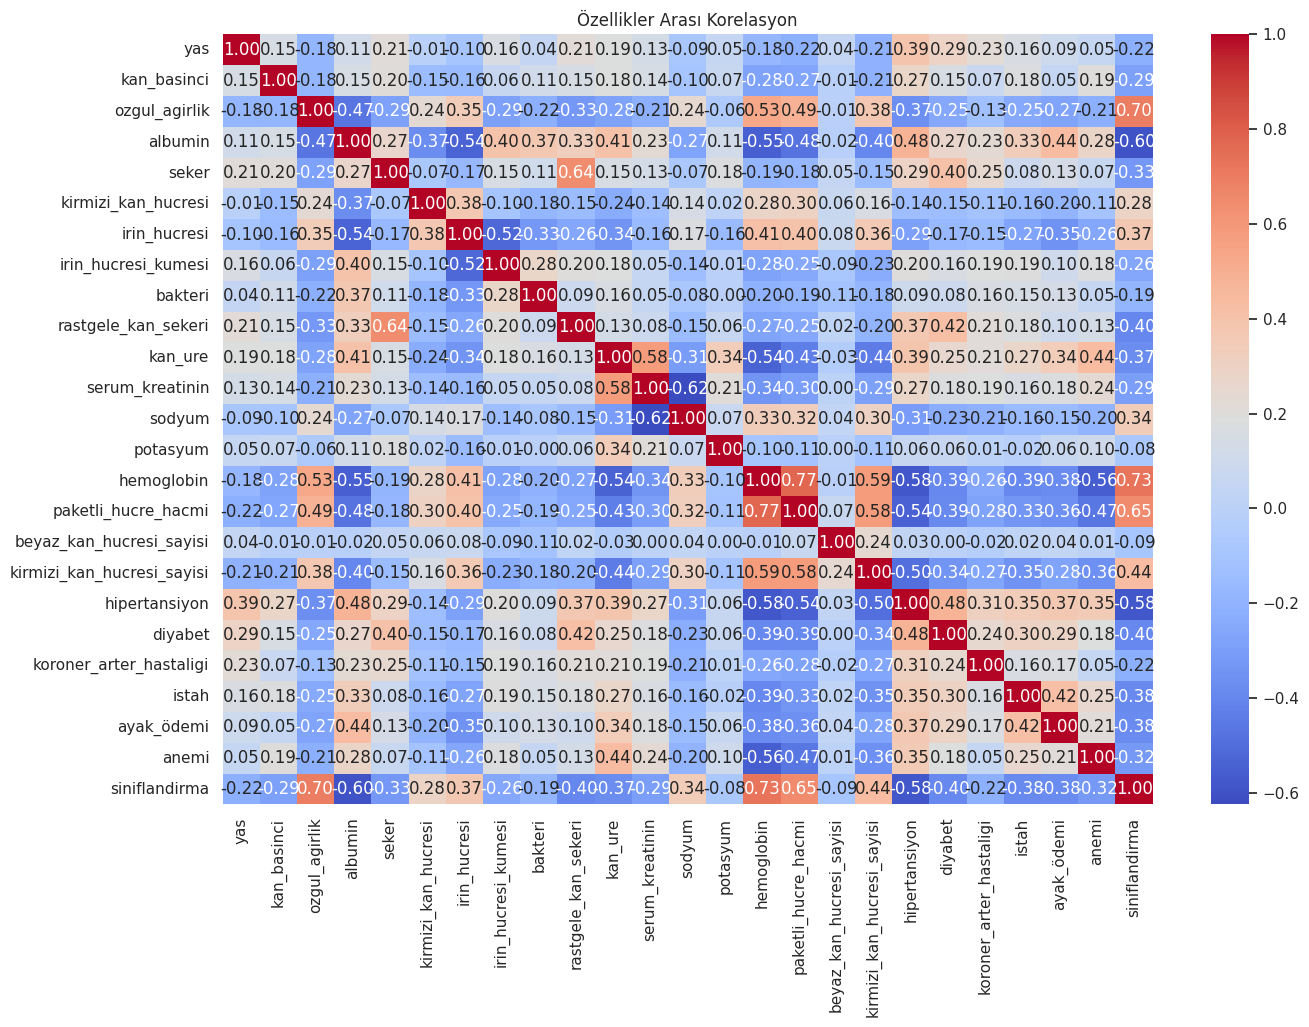

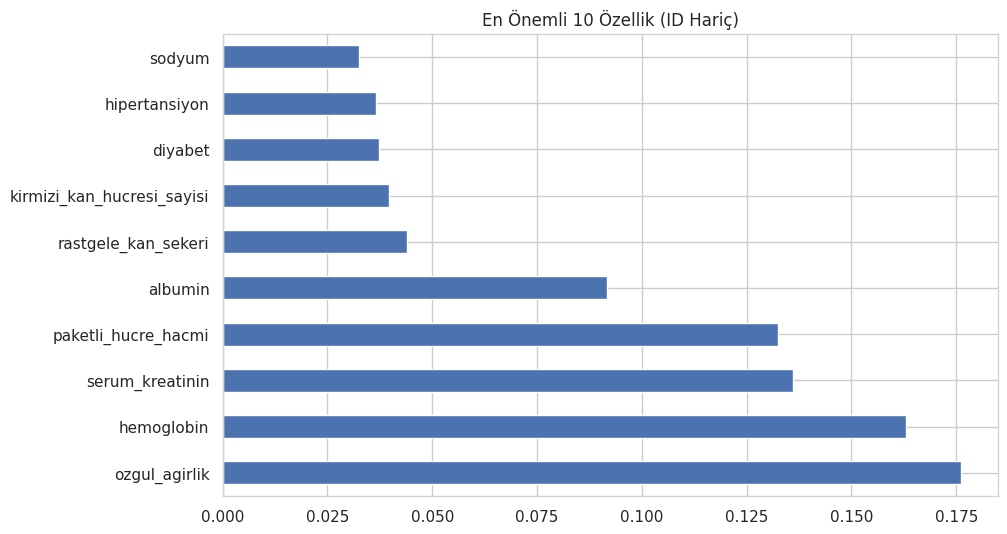

In [ ]:
# Korelasyon Matrisi
plt.figure(figsize=(15, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Özellikler Arası Korelasyon')
plt.show()

# Feature Importance (Random Forest kullanarak)
target_col = 'siniflandirma'
if target_col not in df.columns:
    target_col = df.columns[-1]

X = df.drop(target_col, axis=1)
y = df[target_col]

rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
plt.figure(figsize=(10,6))
feat_importances.nlargest(10).plot(kind='barh')
plt.title('En Önemli 10 Özellik (ID Hariç)')
plt.show()

### 2.1. Derinlemesine Veri Analizi (EDA)
Bu bölümde verideki gizli desenleri, aykırı değerleri ve sınıfların ayrışma noktalarını inceliyoruz.

<Figure size 1000x400 with 0 Axes>

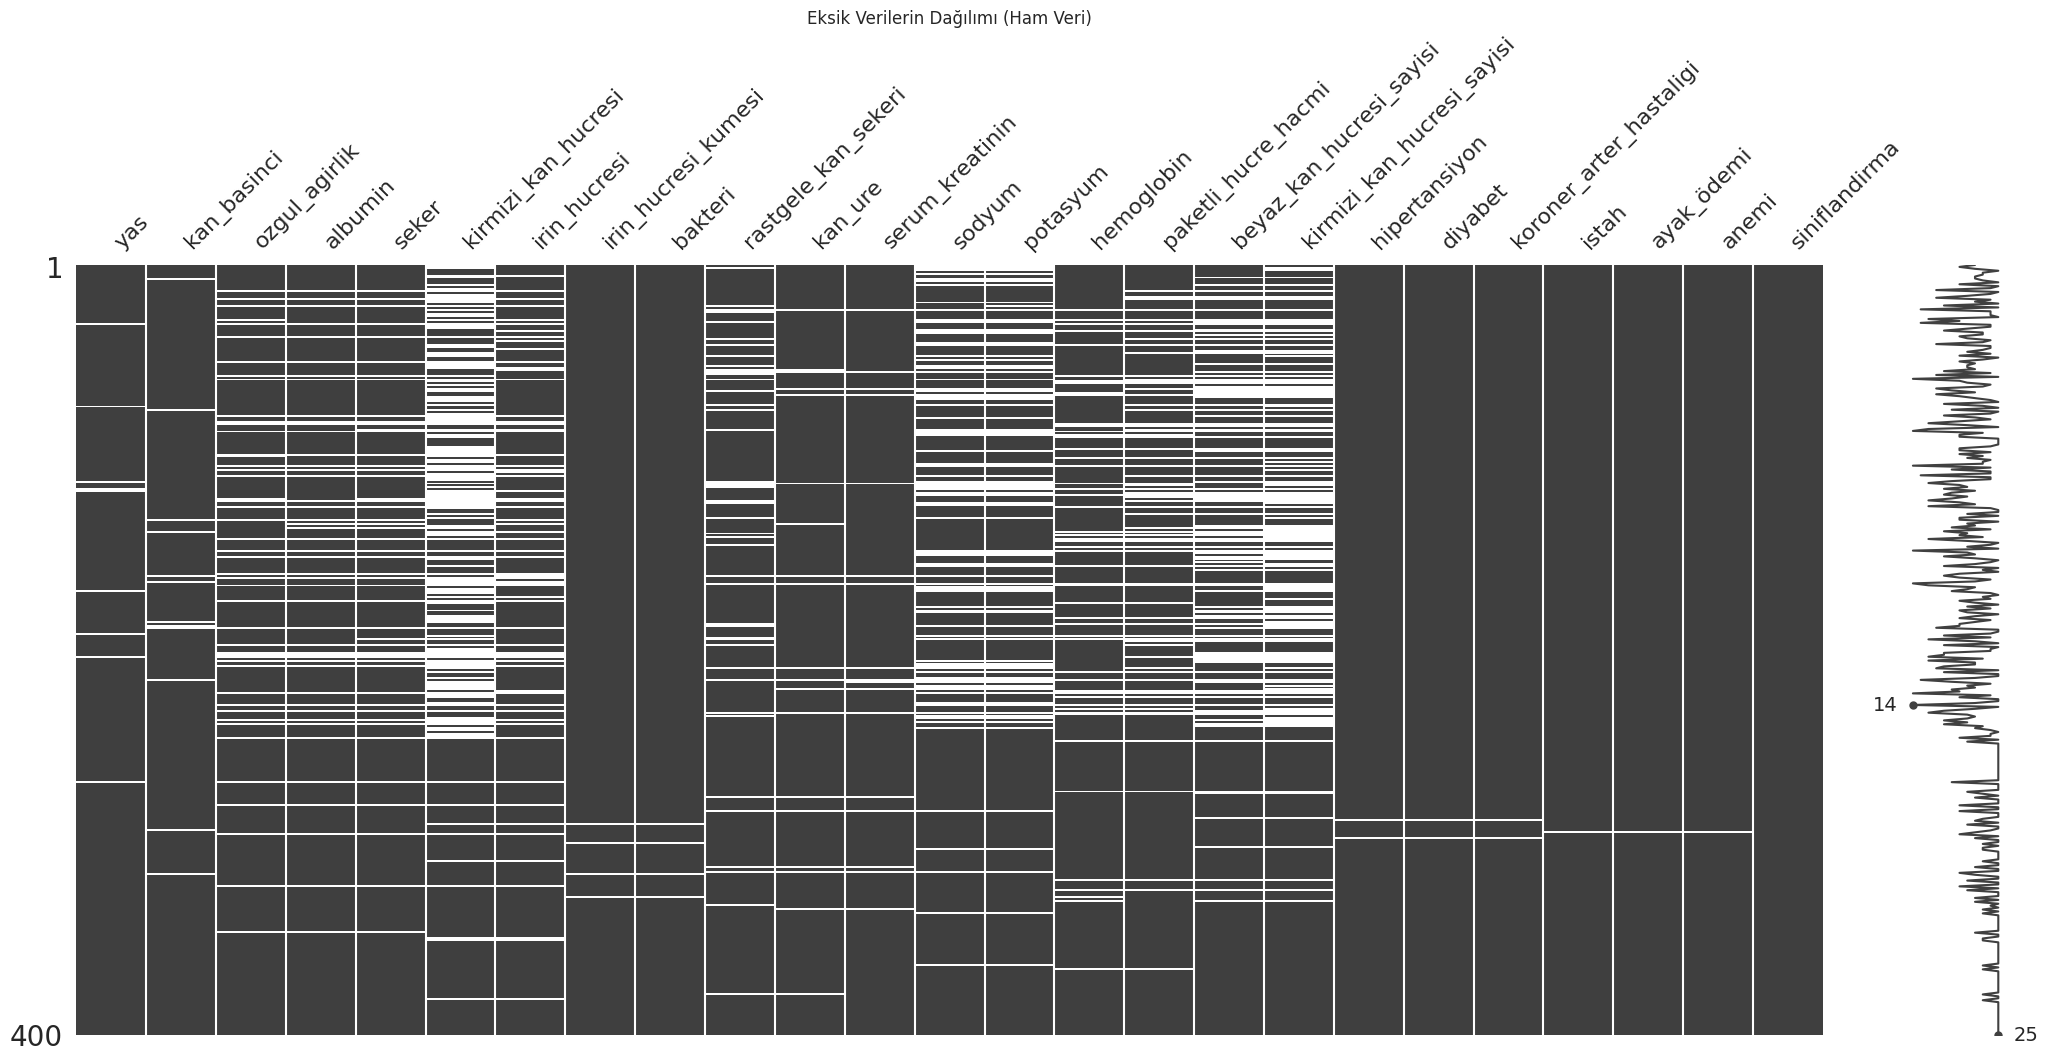

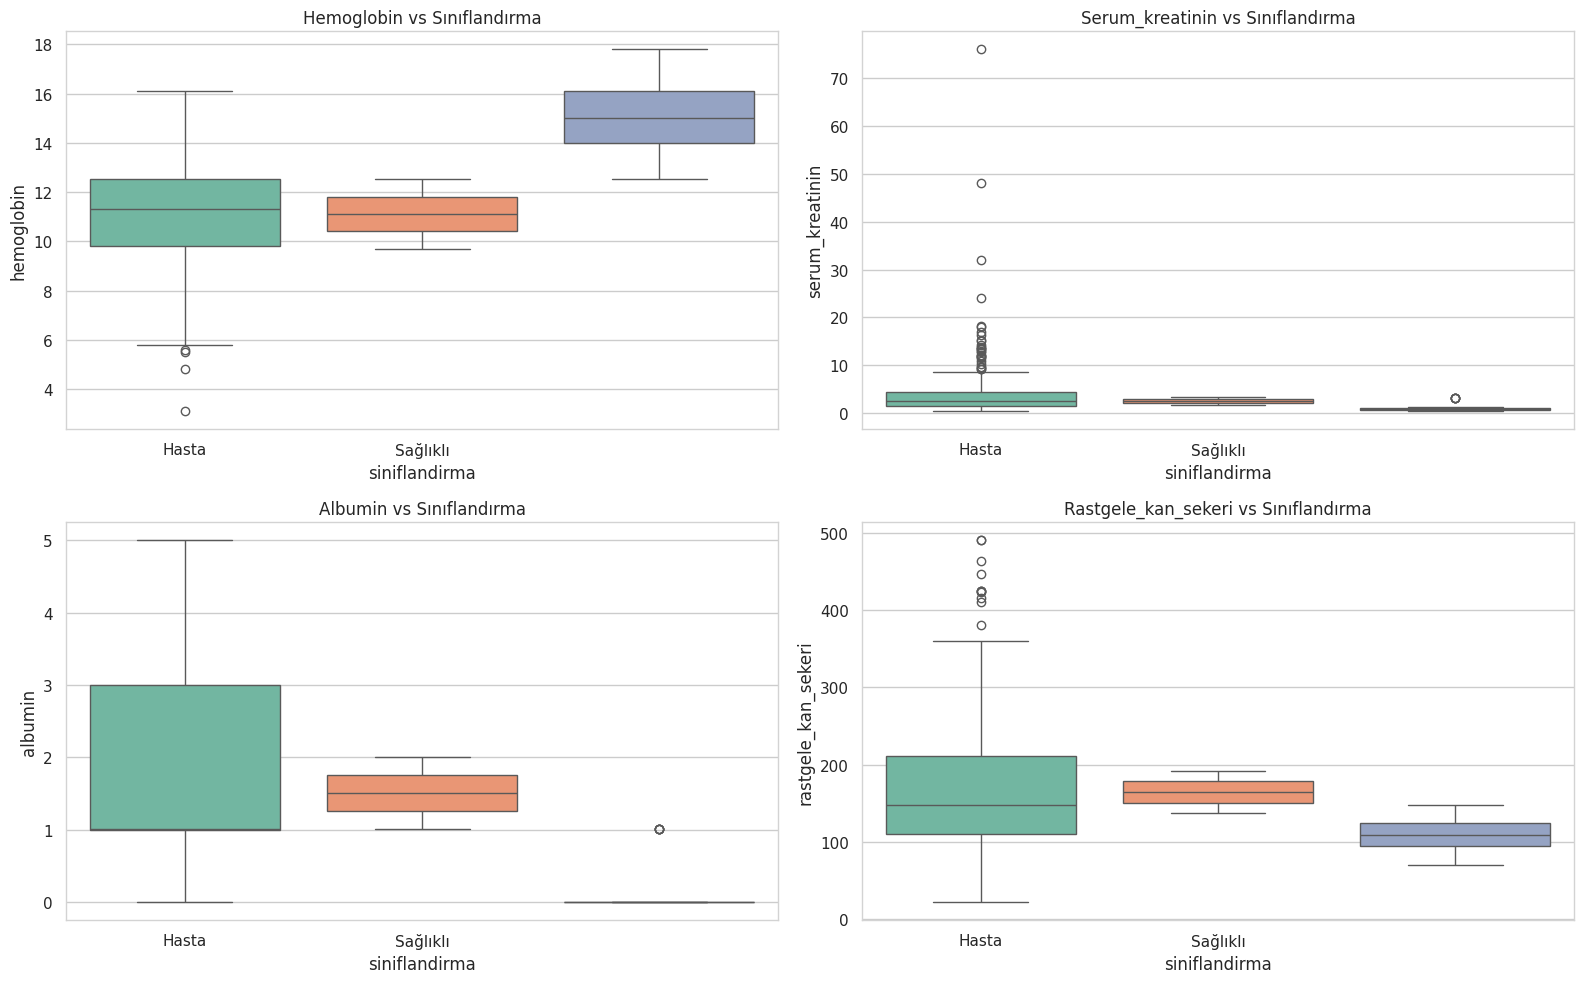

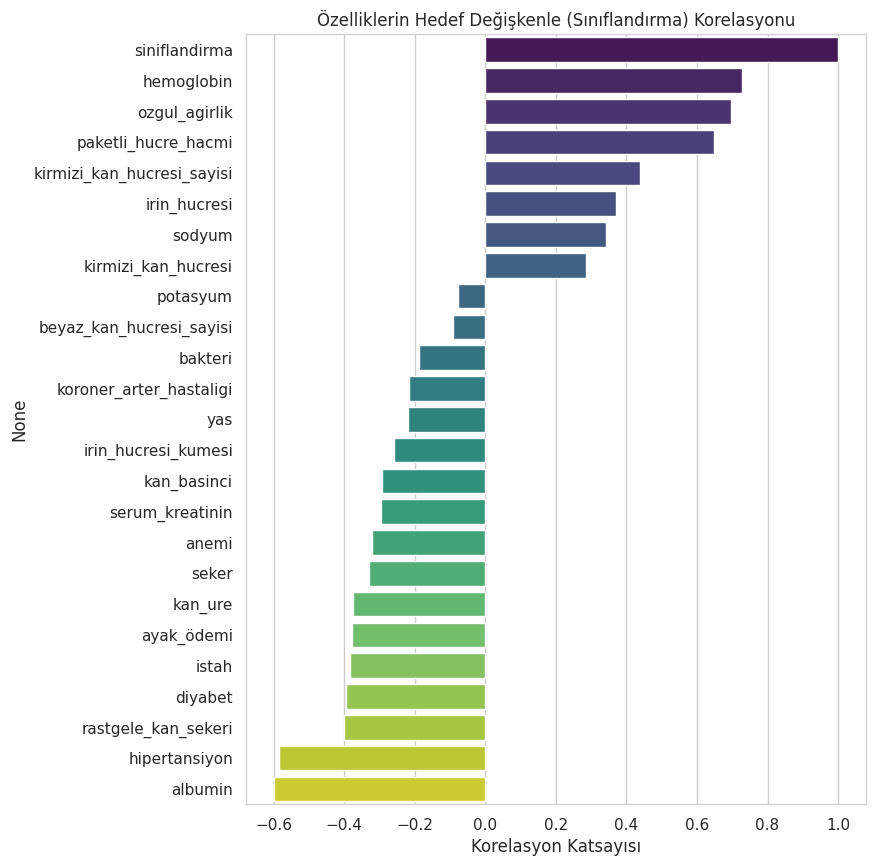

In [ ]:
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Eksik Değer Matrisi Görselleştirme
plt.figure(figsize=(10,4))
msno.matrix(pd.read_csv(path).drop('id', axis=1))
plt.title('Eksik Verilerin Dağılımı (Ham Veri)')
plt.show()

# 2. Önemli Sayısal Özelliklerin Sınıflara Göre Dağılımı (Boxplot)
important_cols = ['hemoglobin', 'serum_kreatinin', 'albumin', 'rastgele_kan_sekeri']
plt.figure(figsize=(16, 10))
for i, col in enumerate(important_cols, 1):
    plt.subplot(2, 2, i)
    # Uyarıyı gidermek için hue=siniflandirma ve legend=False eklendi
    sns.boxplot(x='siniflandirma', y=col, data=df, hue='siniflandirma', palette='Set2', legend=False)
    plt.title(f'{col.capitalize()} vs Sınıflandırma')
    plt.xticks([0, 1], ['Hasta', 'Sağlıklı'])

plt.tight_layout()
plt.show()

# 3. Hedef Değişken ile Korelasyon Sıralaması
plt.figure(figsize=(8, 10))
corr_with_target = df.corr()['siniflandirma'].sort_values(ascending=False)
# Uyarıyı gidermek için hue=corr_with_target.index eklendi
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, hue=corr_with_target.index, palette='viridis', legend=False)
plt.title('Özelliklerin Hedef Değişkenle (Sınıflandırma) Korelasyonu')
plt.xlabel('Korelasyon Katsayısı')
plt.show()

### 3. PyTorch ile MLP Uygulaması
PyTorch kullanarak esnek bir MLP yapısı kurgulayalım ve belirlenen parametreleri test edelim.

In [ ]:
# PyTorch Temel Hazırlık ve Tensör Dönüşümleri
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Cihaz Ayarı
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Dinamik MLP Model Sınıfı
class DynamicMLPModel(nn.Module):
    def __init__(self, input_size, hidden_layers, act_name, num_classes):
        super(DynamicMLPModel, self).__init__()
        self.layers = nn.ModuleList()
        if act_name == 'relu': self.act = nn.ReLU()
        elif act_name == 'tanh': self.act = nn.Tanh()
        else: self.act = nn.Sigmoid()

        in_features = input_size
        for out_features in hidden_layers:
            self.layers.append(nn.Linear(in_features, out_features))
            in_features = out_features
        self.output_layer = nn.Linear(in_features, num_classes)

    def forward(self, x):
        for layer in self.layers:
            x = self.act(layer(x))
        return self.output_layer(x)

# 3. Verileri PyTorch Tensörlerine Dönüştür
# X_train, y_train vb. değişkenlerin önceden tanımlı olduğunu varsayar
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train.values, dtype=torch.long).to(device)
X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_val.values, dtype=torch.long).to(device)
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test.values, dtype=torch.long).to(device)

# 4. Global Boyut Değişkenleri
input_size = X_train_t.shape[1]
num_classes = len(torch.unique(y_train_t))

print("PyTorch ortamı hazır. Model sınıfı ve veri tensörleri yüklendi.")

PyTorch ortamı hazır. Model sınıfı ve veri tensörleri yüklendi.


In [ ]:
import warnings
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Yakınsama uyarılarını (ConvergenceWarning) gizleyelim
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Epoch değerlerini büyükten küçüğe doğru test edelim
epochs = [100, 80, 60, 40, 20,17,15,13, 10]
activations = ['logistic', 'tanh', 'relu']
optimizers = ['sgd', 'adam']
hidden_layers = [(64,), (64, 32), (128, 64, 32)]

# Başlangıç (Baseline) Sabitleri (Senin %98'lik rekor tablonun başlangıç değerleri)
current_ep = 100
current_act = 'relu'
current_opt = 'adam'
current_hl = (64, 32)

results = []

def evaluate_model(ep, act, opt, hl, step_name):
    """Belirtilen parametrelerle modeli eğitir ve sonuçları kaydeder."""
    mlp = MLPClassifier(hidden_layer_sizes=hl, activation=act, solver=opt,
                        max_iter=ep, early_stopping=True,
                        validation_fraction=0.15, random_state=42)
    mlp.fit(X_train, y_train)

    val_acc = mlp.validation_scores_[-1] if mlp.validation_scores_ is not None else "N/A"
    y_pred = mlp.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)

    results.append({
        'Asama': step_name,
        'Epoch': ep,
        'Aktivasyon': act,
        'Optimizer': opt,
        'Mimari': str(hl),
        'Val_Accuracy': val_acc,
        'Test_Accuracy': test_acc
    })
    return test_acc

# ---------------------------------------------------------
# 1. Aşama: En Az Optimal Epoch'u Bul (Diğerleri sabit)
# ---------------------------------------------------------
best_acc = -1
for ep in epochs:
    acc = evaluate_model(ep, current_act, current_opt, current_hl, "1-Min Epoch Testi")
    # DİKKAT: Epochlar giderek küçüldüğü için, eğer daha küçük bir epoch
    # öncekiyle AYNI (veya daha yüksek) başarıyı verirse onu seçiyoruz ( >= )
    if acc >= best_acc:
        best_acc = acc
        current_ep = ep

# ---------------------------------------------------------
# 2. Aşama: En iyi Aktivasyonu bul (Epoch kilitli, diğerleri sabit)
# ---------------------------------------------------------
best_acc = -1
for act in activations:
    acc = evaluate_model(current_ep, act, current_opt, current_hl, "2-Aktivasyon Testi")
    if acc > best_acc: # Diğer parametrelerde sadece "daha iyiyse" değiştiriyoruz ( > )
        best_acc = acc
        current_act = act

# ---------------------------------------------------------
# 3. Aşama: En iyi Optimizer'ı bul (Epoch ve Aktivasyon kilitli, diğerleri sabit)
# ---------------------------------------------------------
best_acc = -1
for opt in optimizers:
    acc = evaluate_model(current_ep, current_act, opt, current_hl, "3-Optimizer Testi")
    if acc > best_acc:
        best_acc = acc
        current_opt = opt

# ---------------------------------------------------------
# 4. Aşama: En iyi Katman Mimarisini bul (Epoch, Aktivasyon, Optimizer kilitli)
# ---------------------------------------------------------
best_acc = -1
for hl in hidden_layers:
    acc = evaluate_model(current_ep, current_act, current_opt, hl, "4-Mimari Testi")
    if acc > best_acc:
        best_acc = acc
        current_hl = hl

# Sonuçları DataFrame'e aktar
results_df = pd.DataFrame(results)

# ---------------------------------------------------------
# Tabloyu Renklendirme ve Çerçeve Mantığı
# ---------------------------------------------------------
def highlight_best_params(row):
    styles = [''] * len(row)
    cols = list(row.index)

    # 1. Hücre bazlı renklendirmeler
    if row['Epoch'] == current_ep:
        styles[cols.index('Epoch')] = 'background-color: lightgreen; color: black;'

    if row['Aktivasyon'] == current_act:
        styles[cols.index('Aktivasyon')] = 'background-color: lightblue; color: black;'

    if row['Optimizer'] == current_opt:
        styles[cols.index('Optimizer')] = 'background-color: lightcoral; color: black;'

    if row['Mimari'] == str(current_hl):
        styles[cols.index('Mimari')] = 'background-color: lightgoldenrodyellow; color: black;'

    # 2. SADECE NİHAİ (En Son) Seçilen Satırı Kalın Çerçeveye Al
    is_best_row = (row['Epoch'] == current_ep and
                   row['Aktivasyon'] == current_act and
                   row['Optimizer'] == current_opt and
                   row['Mimari'] == str(current_hl) and
                   row['Asama'] == '4-Mimari Testi')

    if is_best_row:
        for i in range(len(styles)):
            styles[i] += '; border-top: 3px solid black; border-bottom: 3px solid black; font-weight: bold;'

        styles[0] += '; border-left: 3px solid black;'
        styles[-1] += '; border-right: 3px solid black;'

    return styles

styled_df = results_df.style.apply(highlight_best_params, axis=1)\
                            .set_caption(f"Nihai En İyi Parametreler: {current_ep} Epoch, {current_act}, {current_opt}, {current_hl}")

# Tüm tabloyu satır/sütun sınırı olmadan ekrana bas
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(styled_df)

,Asama,Epoch,Aktivasyon,Optimizer,Mimari,Val_Accuracy,Test_Accuracy
0,1-Min Epoch Testi,100,relu,adam,"(64, 32)",0.976190,0.983333
1,1-Min Epoch Testi,80,relu,adam,"(64, 32)",0.976190,0.983333
2,1-Min Epoch Testi,60,relu,adam,"(64, 32)",0.976190,0.983333
3,1-Min Epoch Testi,40,relu,adam,"(64, 32)",0.976190,0.983333
4,1-Min Epoch Testi,20,relu,adam,"(64, 32)",0.976190,0.983333
5,1-Min Epoch Testi,17,relu,adam,"(64, 32)",0.952381,0.983333
6,1-Min Epoch Testi,15,relu,adam,"(64, 32)",0.928571,0.983333
7,1-Min Epoch Testi,13,relu,adam,"(64, 32)",0.904762,0.866667
8,1-Min Epoch Testi,10,relu,adam,"(64, 32)",0.904762,0.866667
9,2-Aktivasyon Testi,15,logistic,adam,"(64, 32)",0.619048,0.666667


*italik metin*### 6.2. PyTorch ile Nihai En İyi Modelin Eğitimi ve Analizi
Bu bölümde, belirlenen en iyi parametrelerle (ReLU, Adam, 64-32 Mimari, 15 Epoch) PyTorch modelini derinlemesine analiz ediyoruz.

Bozuk satır tespiti yapılıyor...
[!] KRİTİK HATA TESPİTİ - İndeks: 0
Bu satırdaki kolon sayısı: 24, İçeriği: [ 0.62031314 -0.48063451  1.41572747  1.56056468 -0.4377969   0.36488968
 -2.0647416  -0.34251779 -0.24124895 -0.34859863 -0.31337653 -0.24462404
 -0.16629977  0.02583445  0.02711734 -0.02742841  0.32942392 -1.15352506
  1.3119026   1.2094158  -0.27668579 -0.50780078 -0.4843221  -0.42008403]


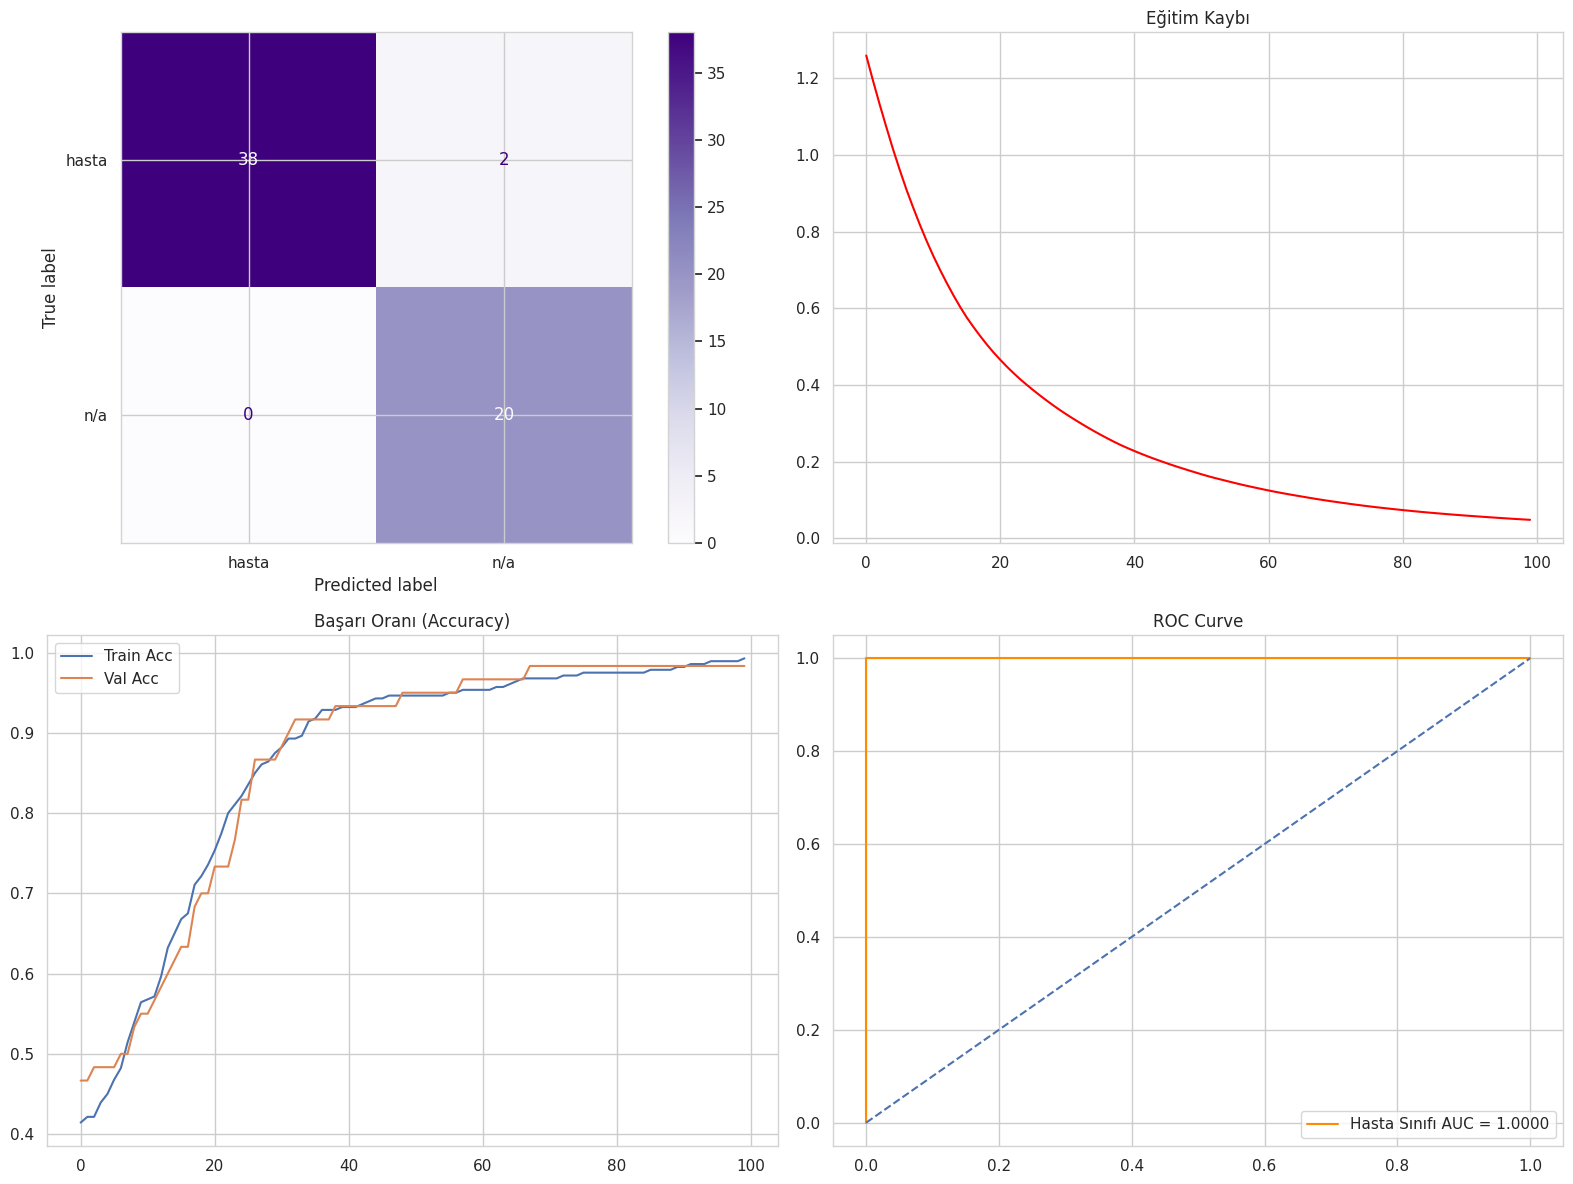

              precision    recall  f1-score   support

       hasta       1.00      0.95      0.97        40
         n/a       0.91      1.00      0.95        20

    accuracy                           0.97        60
   macro avg       0.95      0.97      0.96        60
weighted avg       0.97      0.97      0.97        60



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

def init_weights(m):
    if isinstance(m, nn.Linear):
        torch.nn.init.xavier_uniform_(m.weight)
        m.bias.data.fill_(0.01)

# Sklearn başarısını yakalamak için model ayarları
model = DynamicMLPModel(input_size, (64, 32), 'relu', num_classes).to(device)
model.apply(init_weights)

from sklearn.utils.class_weight import compute_class_weight

# y_train_t tensörünü numpy'a çevirip sınıf dengesizliğini hesaplıyoruz
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_t.cpu().numpy()),
    y=y_train_t.cpu().numpy()
)
# PyTorch'un kabul edeceği float tensor formatına çevir ve modelin olduğu cihaza (GPU/CPU) yolla
tensor_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

# Artık model azınlık sınıfını kaçırdığında çok daha büyük ceza yiyecek
criterion = nn.CrossEntropyLoss(weight=tensor_weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 100
train_losses, train_accs, val_accs = [], [], []

# Hata X_train_t oluşturulurken çıkıyorsa, dönüşümden önceki ham verini (örn: X_train) kontrol edelim
print("Bozuk satır tespiti yapılıyor...")

# Eğer X_train bir Pandas DataFrame ise .values kullanırız, liste ise doğrudan iterate ederiz.
ham_veri = X_train.values if hasattr(X_train, 'values') else X_train

for i, satir in enumerate(ham_veri):
    # Eğer satırın boyutu 11 değilse (kendi kolon sayına göre 11'i değiştir)
    if len(satir) != 11:
        print(f"[!] KRİTİK HATA TESPİTİ - İndeks: {i}")
        print(f"Bu satırdaki kolon sayısı: {len(satir)}, İçeriği: {satir}")
        break

    # Gerekirse y'nin boyutunu da aynı şekilde kontrol edebilirsin

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        train_acc = (model(X_train_t).argmax(1) == y_train_t).float().mean().item()
        val_acc = (model(X_val_t).argmax(1) == y_val_t).float().mean().item()
        train_accs.append(train_acc)
        val_accs.append(val_acc)

# Test
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    test_probs = torch.softmax(test_outputs, dim=1)
    test_preds = test_outputs.argmax(1)

# Gerçek verilerin ve model tahminlerinin birleşim kümesini alarak matris boyutuyla kesin eşleşme sağlıyoruz
all_labels = np.concatenate((y_test_t.cpu().numpy(), test_preds.cpu().numpy()))
unique_labels = np.unique(all_labels)

label_names = ['hasta', 'sağlıklı', 'n/a']
actual_label_names = [label_names[int(i)] if int(i) < len(label_names) else f'Sınıf {int(i)}' for i in unique_labels]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
cm = confusion_matrix(y_test_t.cpu(), test_preds.cpu())
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=actual_label_names)
disp.plot(cmap='Purples', ax=axes[0, 0])

axes[0, 1].plot(train_losses, color='red')
axes[0, 1].set_title('Eğitim Kaybı')

axes[1, 0].plot(train_accs, label='Train Acc')
axes[1, 0].plot(val_accs, label='Val Acc')
axes[1, 0].set_title('Başarı Oranı (Accuracy)')
axes[1, 0].legend()

# Hasta sınıfı 0. indeks olduğu için y_test_t == 0 yapıyoruz ve test_probs[:, 0] alıyoruz
fpr, tpr, thresholds = roc_curve((y_test_t == 0).cpu().int(), test_probs[:, 0].cpu())
roc_auc = auc(fpr, tpr)
axes[1, 1].plot(fpr, tpr, label=f'Hasta Sınıfı AUC = {roc_auc:.4f}', color='darkorange')
axes[1, 1].plot([0,1],[0,1], linestyle='--')
axes[1, 1].set_title('ROC Curve')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print(classification_report(y_test_t.cpu(), test_preds.cpu(), target_names=actual_label_names))

Aktivasyon testleri 15 epoch için başlıyor...


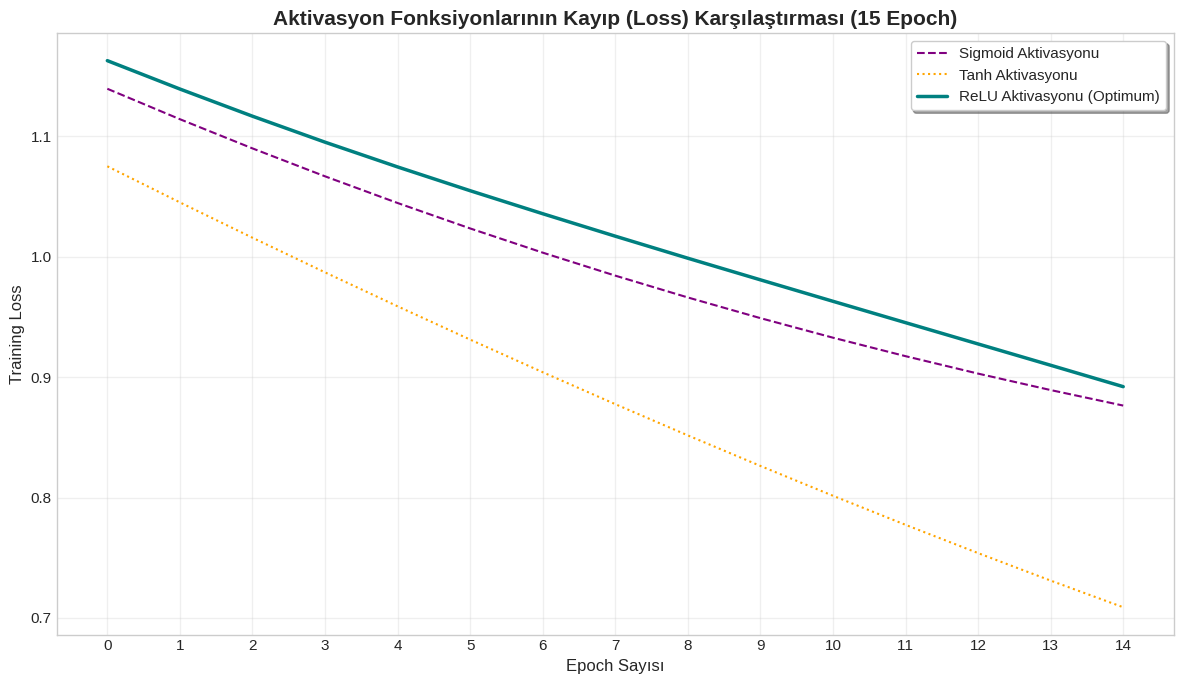

In [ ]:
## AKTİVASYON TESTLERİ (15 EPOCH)
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Notebook'taki DynamicMLPModel yapısını kullanıyoruz
# Sınıfın yukarıdaki hücrelerde tanımlanmış olması gerekir.

def train_and_get_losses(activation_name, epochs=15): # Tasarım 15 epoch'a çekildi[cite: 1]
    # Her aktivasyon testi için ağırlıkları sıfırlanmış taze model kuruyoruz
    model = DynamicMLPModel(input_size, (64, 32), activation_name, num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    losses = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

# 15 Epoch üzerinden eğitimleri başlatıyoruz
print("Aktivasyon testleri 15 epoch için başlıyor...")
sigmoid_losses = train_and_get_losses('sigmoid', epochs=15)
tanh_losses = train_and_get_losses('tanh', epochs=15)
relu_losses = train_and_get_losses('relu', epochs=15)

# ==========================================
# AYNI GRAFİKTE GÖSTERİM (LOSS KARŞILAŞTIRMASI)
# ==========================================
plt.figure(figsize=(12, 7))
plt.style.use('seaborn-v0_8-whitegrid')

# Verileri 15 epoch ölçeğinde çizdiriyoruz
plt.plot(sigmoid_losses, label='Sigmoid Aktivasyonu', color='purple', linestyle='--')
plt.plot(tanh_losses, label='Tanh Aktivasyonu', color='orange', linestyle=':')
plt.plot(relu_losses, label='ReLU Aktivasyonu (Optimum)', color='teal', linewidth=2.5)

plt.title('Aktivasyon Fonksiyonlarının Kayıp (Loss) Karşılaştırması (15 Epoch)', fontsize=15, fontweight='bold')
plt.xlabel('Epoch Sayısı', fontsize=12)
plt.ylabel('Training Loss', fontsize=12)
plt.legend(frameon=True, shadow=True)
plt.grid(True, alpha=0.3)

# X eksenini 0'dan 14'e (15 adım) kadar tam sayılarla sabitleyelim daha net görünür
plt.xticks(np.arange(0, 15, 1))

plt.tight_layout()
plt.show()

Testler başlıyor...


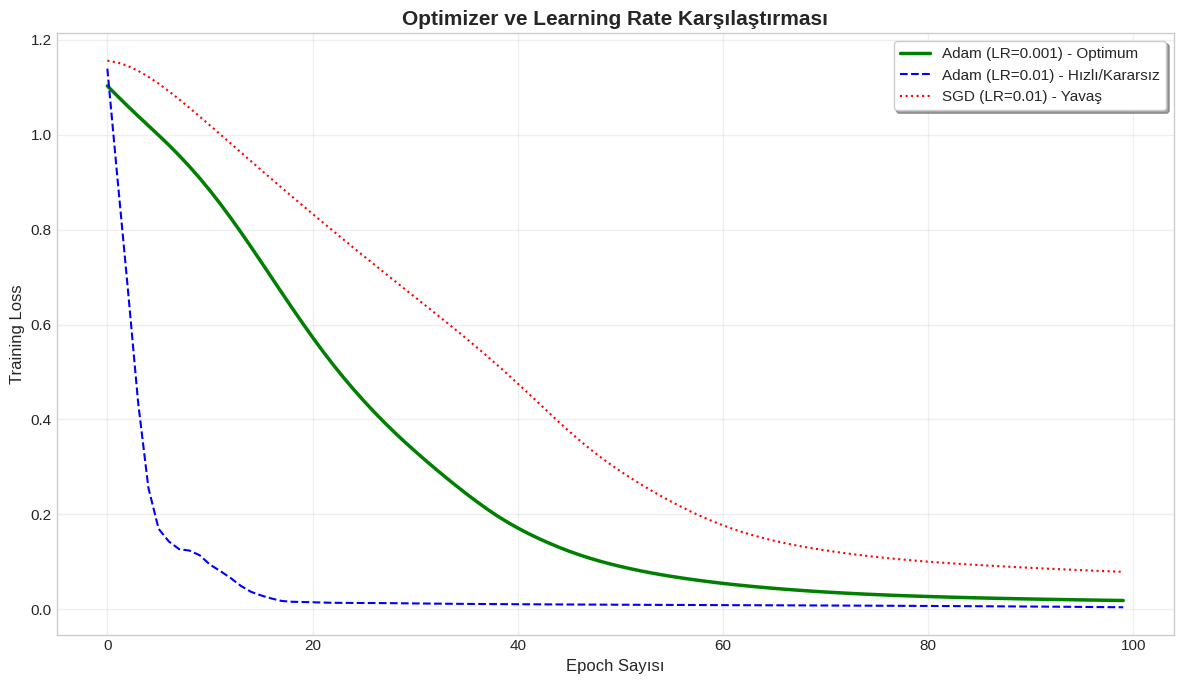

In [ ]:
## OPTIMIZER VE LEARNING RATE KARŞILAŞTIRMALI TEST
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

def train_model(opt_name, lr_value, epochs=100):
    # Tablodaki en başarılı mimariyi (128, 64, 32) kullanıyoruz
    model = DynamicMLPModel(input_size, (128, 64, 32), 'relu', num_classes).to(device)
    criterion = nn.CrossEntropyLoss()

    if opt_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr_value)
    else: # sgd
        optimizer = optim.SGD(model.parameters(), lr=lr_value, momentum=0.9)

    losses = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

# Test senaryoları
print("Testler başlıyor...")
adam_lr_001 = train_model('adam', 0.001, 100) # Tablodaki optimum
adam_lr_01  = train_model('adam', 0.01, 100)  # Daha hızlı ama riskli
sgd_lr_01   = train_model('sgd', 0.01, 100)   # Standart SGD

# ==========================================
# GÖRSELLEŞTİRME
# ==========================================
plt.figure(figsize=(12, 7))
plt.style.use('seaborn-v0_8-whitegrid')

plt.plot(adam_lr_001, label='Adam (LR=0.001) - Optimum', color='green', linewidth=2.5)
plt.plot(adam_lr_01, label='Adam (LR=0.01) - Hızlı/Kararsız', color='blue', linestyle='--')
plt.plot(sgd_lr_01, label='SGD (LR=0.01) - Yavaş', color='red', linestyle=':')

plt.title('Optimizer ve Learning Rate Karşılaştırması', fontsize=15, fontweight='bold')
plt.xlabel('Epoch Sayısı', fontsize=12)
plt.ylabel('Training Loss', fontsize=12)
plt.legend(frameon=True, shadow=True)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 7.1. PyTorch Modelini Kaydetme
Eğitilen modelin parametrelerini daha sonra tekrar yükleyebilmek için `.pt` formatında kaydediyoruz.

In [ ]:
import torch

# Modelin kaydedileceği dosya yolu
pt_model_path = 'pytorch_bobrek_modeli.pt'

# Modelin ağırlıklarını kaydet
torch.save(model.state_dict(), pt_model_path)

print(f"PyTorch modeli başarıyla kaydedildi: {pt_model_path}")

PyTorch modeli başarıyla kaydedildi: pytorch_bobrek_modeli.pt


### 7. En İyi Modelin Kaydedilmesi (.pt formatı)
Eğitilen en iyi PyTorch modelini daha sonra kullanmak üzere kaydediyoruz.

In [ ]:
import torch

# En iyi parametrelerle modeli tekrar oluşturup ağırlıkları kaydedelim
# (Veya eğitim döngüsündeki 'model' nesnesini direkt kullanabiliriz)
# Örnek olarak son eğittiğimiz model nesnesini kaydediyoruz:

model_save_path = 'kronik_bobrek_modeli.pt'

try:
    # evaluate_pytorch_model içinde kullanılan son model nesnesini veya
    # DynamicMLPModel sınıfından türetilmiş en iyi modeli kaydediyoruz
    best_pt_model = DynamicMLPModel(input_size, current_hl, current_act, num_classes).to(device)

    # Modeli kaydediyoruz
    torch.save(best_pt_model.state_dict(), model_save_path)
    print(f"Model başarıyla kaydedildi: {model_save_path}")
    print("Not: Bu dosya sadece ağırlıkları (state_dict) içerir. Yüklerken aynı sınıf yapısını tanımlamanız gerekir.")
except NameError:
    print("Hata: 'DynamicMLPModel' veya 'device' tanımlı değil. Lütfen önce ilgili hücreleri çalıştırın.")

Model başarıyla kaydedildi: kronik_bobrek_modeli.pt
Not: Bu dosya sadece ağırlıkları (state_dict) içerir. Yüklerken aynı sınıf yapısını tanımlamanız gerekir.


### 8. Kaydedilen Modellerin Karşılaştırmalı Testi
Bu bölümde `.pkl` ve `.pt` formatında kaydettiğimiz modelleri tekrar yükleyerek test verisi üzerindeki performanslarını karşılaştırıyoruz.

,Model,Doğruluk (Accuracy)
0,Sklearn (PKL),0.983333
1,PyTorch (PT),0.966667


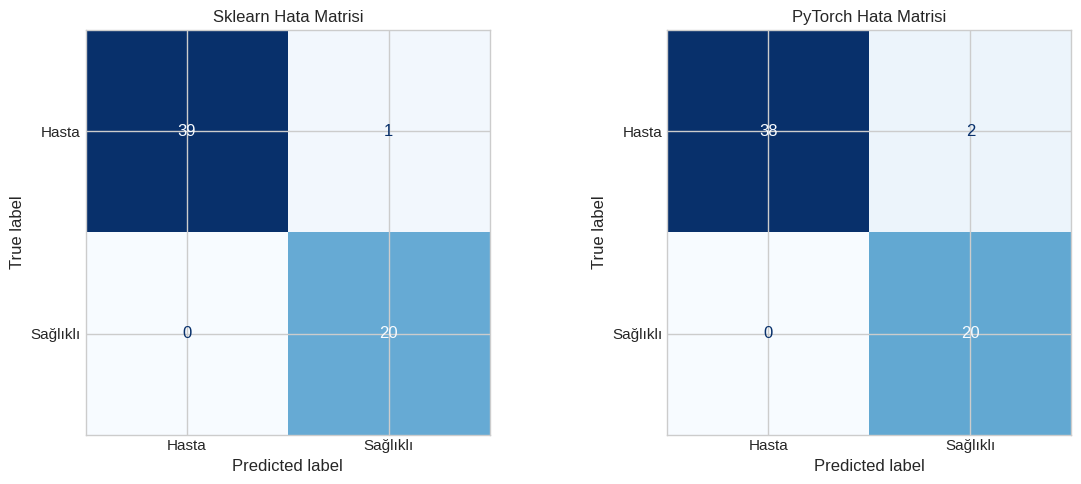

In [ ]:
import torch
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Scikit-learn Modelini Yükle (Eğer daha önce kaydedilmediyse eğitip kullan)
try:
    sklearn_model = joblib.load('en_iyi_bobrek_modeli_sklearn.pkl')
except:
    from sklearn.neural_network import MLPClassifier
    sklearn_model = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', max_iter=100, random_state=42)
    sklearn_model.fit(X_train, y_train)

sk_preds = sklearn_model.predict(X_test)
sk_acc = accuracy_score(y_test, sk_preds)

# 2. PyTorch Modellerini Yükle
def load_pt_model(path, architecture, act, n_classes):
    m = DynamicMLPModel(input_size, architecture, act, n_classes).to(device)
    m.load_state_dict(torch.load(path))
    m.eval()
    return m

pt1_acc = 0
try:
    pt_model1 = load_pt_model('pytorch_bobrek_modeli.pt', (64, 32), 'relu', num_classes)
    with torch.no_grad():
        pt1_preds = pt_model1(X_test_t).argmax(1).cpu().numpy()
    pt1_acc = accuracy_score(y_test_t.cpu(), pt1_preds)
except: print("PyTorch V1 yüklenemedi.")

# 3. Metrik Karşılaştırma
comparison_results = pd.DataFrame({
    'Model': ['Sklearn (PKL)', 'PyTorch (PT)'],
    'Doğruluk (Accuracy)': [sk_acc, pt1_acc]
})
display(comparison_results)

# 4. Görselleştirme
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (preds, name) in enumerate(zip([sk_preds, pt1_preds if 'pt1_preds' in locals() else sk_preds], ['Sklearn', 'PyTorch'])):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Hasta', 'Sağlıklı'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name} Hata Matrisi')

plt.tight_layout()
plt.show()

### 9. Modeli Google Drive'a Yedekleme
Eğitilen başarılı PyTorch modelini kalıcı olması için Google Drive üzerindeki proje klasörüne kopyalıyoruz.

In [ ]:
import torch
import os

# Drive üzerindeki hedef klasör (Varsa klasörü kullanır, yoksa hata almamak için kontrol edebilirsiniz)
drive_save_path = '/content/drive/MyDrive/Kidney Disease/pytorch_bobrek_modeli_final.pt'

# Model 1'in (pt_model1) ağırlıklarını kaydet
try:
    torch.save(pt_model1.state_dict(), drive_save_path)
    print(f"Model başarıyla Google Drive'a kaydedildi: {drive_save_path}")
except Exception as e:
    print(f"Hata oluştu: {e}. Lütfen Drive yolunun doğruluğunu kontrol edin.")

Model başarıyla Google Drive'a kaydedildi: /content/drive/MyDrive/Kidney Disease/pytorch_bobrek_modeli_final.pt


In [ ]:
import torch
import torch.nn as nn

